<a href="https://colab.research.google.com/github/Madss28/Madss28/blob/main/Customer_Churn_Prediction_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

In [22]:
url = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/"
    "Telco-Customer-Churn.csv"
)

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate customer IDs:")
print(df["customerID"].duplicated().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts(normalize=True) * 100)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecur

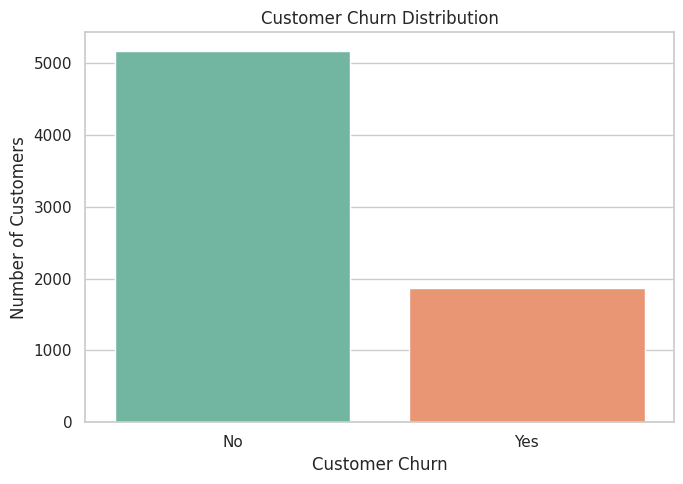

In [24]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


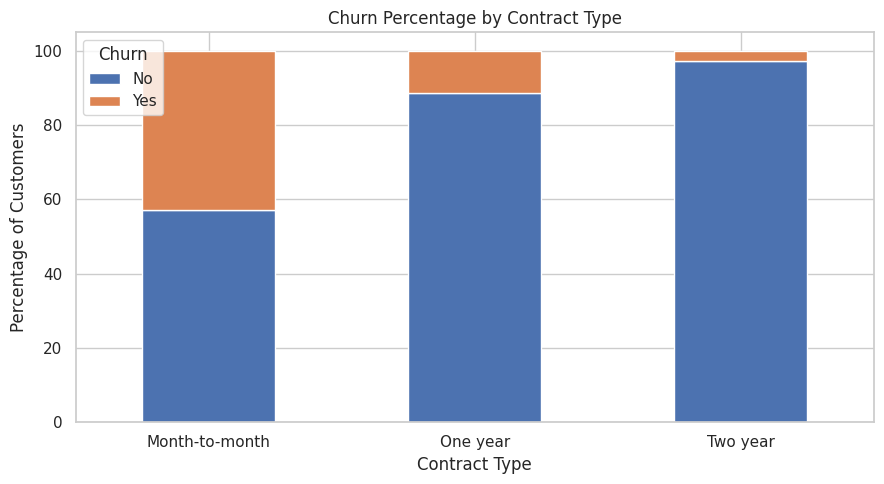

In [25]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

display(contract_churn.round(2))

contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Churn Percentage by Contract Type")
plt.ylabel("Percentage of Customers")
plt.xlabel("Contract Type")
plt.xticks(rotation=0)
plt.legend(title="Churn")

plt.tight_layout()
plt.show()

In [26]:
df_clean = df.copy()

# Convert TotalCharges into numeric values
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Convert target to binary
df_clean["Churn"] = df_clean["Churn"].map({
    "Yes": 1,
    "No": 0
})

# Remove identifier column
df_clean = df_clean.drop(columns=["customerID"])

print("Missing values after conversion:")
print(df_clean.isnull().sum().sort_values(ascending=False).head())

display(df_clean.head())

Missing values after conversion:
TotalCharges     11
gender            0
Partner           0
SeniorCitizen     0
Dependents        0
dtype: int64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [27]:
X = df_clean.drop(columns=["Churn"])
y = df_clean["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5634
Testing samples: 1409


In [28]:
numeric_features = [
    "tenure", "MonthlyCharges", "TotalCharges"
]

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [29]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression Results:")
print(classification_report(y_test, logistic_predictions))

logistic_auc = roc_auc_score(
    y_test,
    logistic_model.predict_proba(X_test)[:, 1]
)

print("ROC-AUC:", round(logistic_auc, 3))

Logistic Regression Results:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.841


In [30]:
forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_test)

print("Random Forest Results:")
print(classification_report(y_test, forest_predictions))

forest_auc = roc_auc_score(
    y_test,
    forest_model.predict_proba(X_test)[:, 1]
)

print("ROC-AUC:", round(forest_auc, 3))

Random Forest Results:
              precision    recall  f1-score   support

           0       0.89      0.79      0.84      1035
           1       0.55      0.72      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409

ROC-AUC: 0.839


In [31]:
from sklearn.metrics import precision_score, recall_score, f1_score

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Precision": [
        precision_score(y_test, logistic_predictions),
        precision_score(y_test, forest_predictions)
    ],
    "Recall": [
        recall_score(y_test, logistic_predictions),
        recall_score(y_test, forest_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, logistic_predictions),
        f1_score(y_test, forest_predictions)
    ],
    "ROC-AUC": [logistic_auc, forest_auc]
})

display(results.round(3))

,Model,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.503,0.783,0.613,0.841
1,Random Forest,0.553,0.717,0.624,0.839


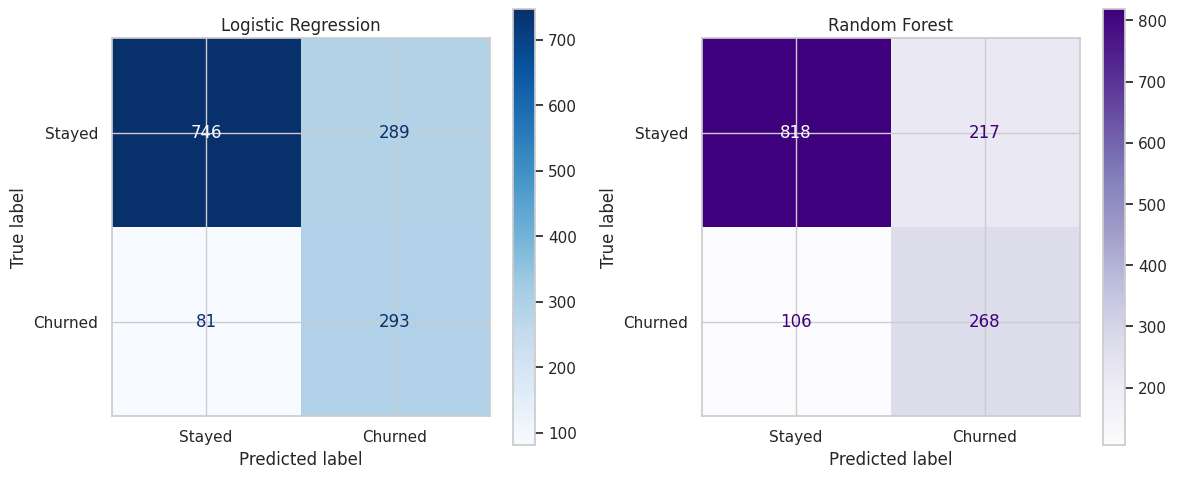

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    display_labels=["Stayed", "Churned"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    forest_predictions,
    display_labels=["Stayed", "Churned"],
    cmap="Purples",
    ax=axes[1]
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

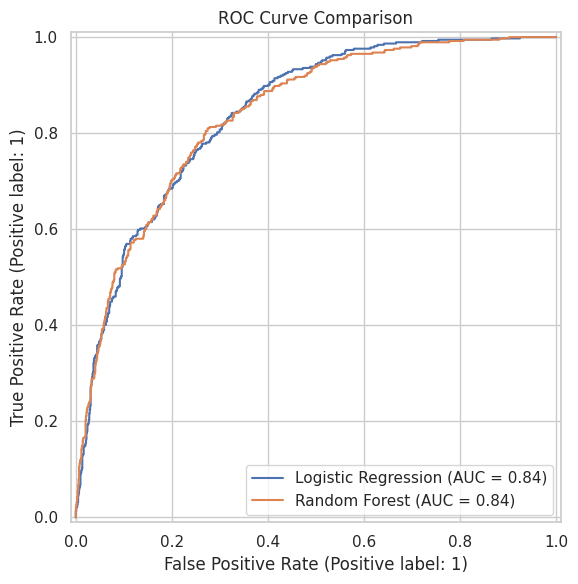

In [33]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(
    logistic_model, X_test, y_test,
    name="Logistic Regression", ax=ax
)

RocCurveDisplay.from_estimator(
    forest_model, X_test, y_test,
    name="Random Forest", ax=ax
)

plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

,Feature,Importance
14,Contract,0.062158
4,tenure,0.025414
7,InternetService,0.016852
18,TotalCharges,0.010043
8,OnlineSecurity,0.006540
11,TechSupport,0.005738
3,Dependents,0.002574
15,PaperlessBilling,0.002538
16,PaymentMethod,0.002183
12,StreamingTV,0.001660


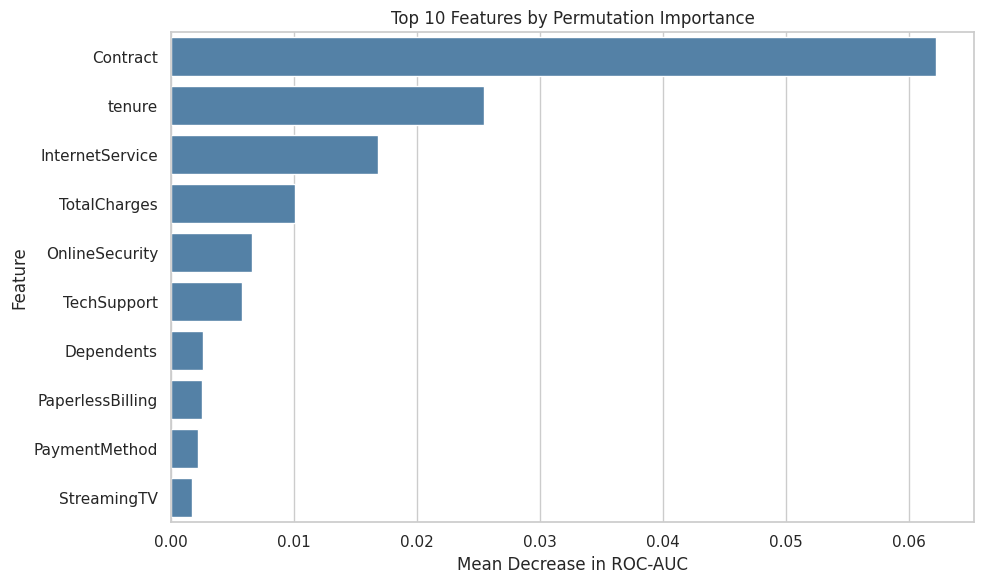

In [34]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    forest_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(feature_importance.head(10))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 10 Features by Permutation Importance")
plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [35]:
import os

os.makedirs("outputs", exist_ok=True)

results.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "outputs/feature_importance.csv",
    index=False
)

df_clean.to_csv(
    "outputs/cleaned_customer_data.csv",
    index=False
)

print("Project results saved!")

Project results saved!


In [36]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": forest_model
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "f1": "f1",
            "recall": "recall"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std(),
        "Mean F1": scores["test_f1"].mean(),
        "Mean Recall": scores["test_recall"].mean()
    })

cv_summary = pd.DataFrame(cv_results)

display(cv_summary.round(3))

,Model,Mean ROC-AUC,ROC-AUC Std,Mean F1,Mean Recall
0,Logistic Regression,0.846,0.012,0.629,0.801
1,Random Forest,0.843,0.009,0.632,0.704


In [37]:
cv_summary.to_csv(
    "outputs/cross_validation_results.csv",
    index=False
)

print("Cross-validation results saved!")

Cross-validation results saved!


**Customer Churn Prediction Using Machine Learning**

Developed a machine learning project to predict customer churn using the IBM Telco Customer Churn dataset, containing over 7,000 customer records. Performed data cleaning, exploratory data analysis and feature preprocessing before training and comparing Logistic Regression and Random Forest models.

Evaluated model performance using precision, recall, F1-score, ROC-AUC and cross-validation techniques. Both models achieved ROC-AUC scores of approximately 0.84. Applied permutation feature importance to identify key predictors of churn, including contract type, customer tenure and internet service.

Technologies: Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn, Machine Learning, Model Evaluation, Google Colab.